In [ ]:
import numpy as np
from math import pi, sqrt
import matplotlib.pyplot as plt

# Importing standard Qiskit libraries
from qiskit import QuantumCircuit, transpile, Aer, IBMQ, execute, QuantumRegister
from qiskit.tools.jupyter import *
from qiskit.visualization import * # plot_bloch_multivector
from ibm_quantum_widgets import * # CircuitComposer
from qiskit.providers.aer import QasmSimulator
from qiskit.quantum_info import Statevector

# Loading your IBM Quantum account(s)
provider = IBMQ.load_account()

<frozen importlib._bootstrap>:219: RuntimeWarning: scipy._lib.messagestream.MessageStream size changed, may indicate binary incompatibility. Expected 56 from C header, got 64 from PyObject


In [ ]:
circuit = QuantumCircuit(2,2)
editor2 = CircuitComposer(circuit=circuit)
editor2

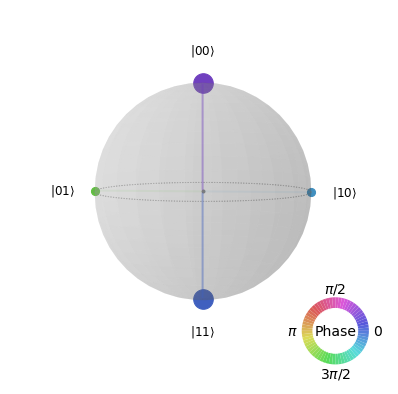

In [169]:
qc2 = editor2.circuit
plot_state_qsphere(qc2)

Statevector([ 0.65328148+0.j        , -0.25      -0.10355339j,
              0.13529903-0.23434479j,  0.51828305-0.39769257j],
            dims=(2, 2))
z1,z2,z =  (0.79+0.61j) (-0.13-0.99j) (-0.71+0.7j)


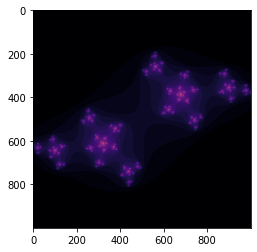

In [170]:
qc2 = editor2.circuit
backend = Aer.get_backend('statevector_simulator')
out = execute(qc2,backend).result().get_statevector()
print(out)

a00 = out.data[0]
a01 = out.data[1]
a10 = out.data[2]
a11 = out.data[3]

if a11.real != 0 or a11.imag != 0:
    z1 = a00/a11
    z1 = round(z1.real, 2) + round(z1.imag, 2) * 1j
else:
     z1 = 0
        
#print("z1= ",z1)

if a10.real != 0 or a10.imag != 0:
    z2 = a01/a10
    z2 = round(z2.real, 2) + round(z2.imag, 2) * 1j
else:
     z2 = 0
        
#print("z2= ",z2)

if z2.real != 0 or z2.imag != 0:
    z = z1/z2 # (z1+z2)/2
    z = round(z.real, 2) + round(z.imag, 2) * 1j
else:
     z = 0
        
print("z1,z2,z = ",z1,z2,z)


#z = -0.4+0.6j
heightsize = 1000 # 800
widthsize = heightsize # 1000


def julia_set(c=z, height=heightsize, width=widthsize, x=0, y=0, zoom=1, max_iterations=100):
    # To make navigation easier we calculate these values
    x_width = 1.5
    y_height = 1.5*height/width
    x_from = x - x_width/zoom
    x_to = x + x_width/zoom
    y_from = y - y_height/zoom
    y_to = y + y_height/zoom
    # Here the actual algorithm starts
    x = np.linspace(x_from, x_to, width).reshape((1, width))
    y = np.linspace(y_from, y_to, height).reshape((height, 1))
    z = x + 1j * y
    # Initialize z to all zero
    c = np.full(z.shape, c)
    # To keep track in which iteration the point diverged
    div_time = np.zeros(z.shape, dtype=int)
    # To keep track on which points did not converge so far
    m = np.full(c.shape, True, dtype=bool)
    for i in range(max_iterations):
        z[m] = z[m]**2 + c[m]
        m[np.abs(z) > 2] = False
        div_time[m] = i
    return div_time


#f, axarr = plt.subplots(1,3,figsize=(12, 12))
#axarr[0].imshow(julia_set(c=z1), cmap='magma')
#axarr[1].imshow(julia_set(c=z2), cmap='magma')
#axarr[2].imshow(julia_set(c=z), cmap='magma')

plt.imshow(julia_set(), cmap='magma') # viridis', 'plasma', 'inferno', 'magma', 'cividis'
plt.show()

#plt.savefig('plots/2qubit_simulator_reversebell_state1_U_pi4_-pi3_pi8.png')

## Running on a real quantum computer
### Identify least busy system, perform measurements and run on backend

In [171]:
# Find the least busy system that has at least 2 qubits
from qiskit.providers.ibmq import least_busy

ibmq_backend = least_busy(provider.backends(filters=lambda x: x.configuration().n_qubits >= 2 and 
                                   not x.configuration().simulator and x.status().operational==True))

print(ibmq_backend)

ibmq_lima


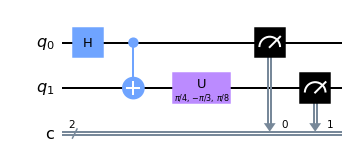

In [172]:
qc2.measure([0,1], [0,1])
qc2.draw()

In [175]:
#ibmq_backend
shotno=1024
job_ibmq = execute(qc2, ibmq_backend, shots=shotno)
result = job_ibmq.result()

## Perform calculations and plot results

Statevector probilities of measuring the basis states:  0.427 0.073 0.073 0.427
Observed probabilities of measuring the computational basis states 0.381 0.071 0.13 0.418
z,zqc =  (-0.71+0.7j) (-0.9110869196953963+0.9110869196953962j)


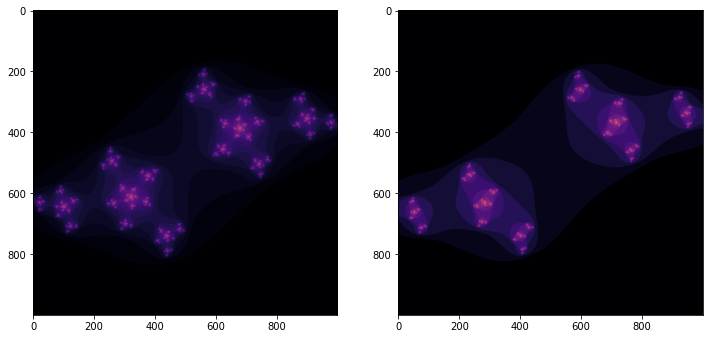

In [176]:
#job_ibmq = execute(qc2, ibmq_backend, shots=1024)
#result = job_ibmq.result()
prob00statevec = out.probabilities()[0]
prob01statevec = out.probabilities()[1]
prob10statevec = out.probabilities()[2]
prob11statevec = out.probabilities()[3]
print("Statevector probilities of measuring the basis states: ", round(prob00statevec,3), round(prob01statevec,3), round(prob10statevec,3),round(prob11statevec,3))

counts = result.get_counts()
prob00qc = counts['00']/shotno
prob01qc = counts['01']/shotno
prob10qc = counts['10']/shotno
prob11qc = counts['11']/shotno
print("Observed probabilities of measuring the computational basis states", round(prob00qc,3), round(prob01qc,3),round(prob10qc,3),round(prob11qc,3))



# one simple approach # amplitude^2 = probability
a00qc = a00*sqrt(prob00qc/prob00statevec)
a01qc = a01*sqrt(prob01qc/prob01statevec)
a10qc = a10*sqrt(prob10qc/prob10statevec)
a11qc = a11*sqrt(prob11qc/prob11statevec)

z1qc = a00qc/a11qc
z2qc = a01qc/a10qc
zqc = z1qc/z2qc
print("z,zqc = ",z,zqc)

#plt.imshow(julia_set(c=zqc), cmap='magma')
f, axarr = plt.subplots(1,2,figsize=(12, 12))
axarr[0].imshow(julia_set(c=z), cmap='magma')
axarr[1].imshow(julia_set(c=zqc), cmap='magma')

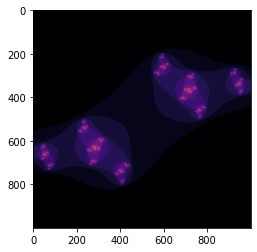

In [182]:
plt.imshow(julia_set(c=zqc), cmap='magma')
#plt.savefig('plots/2qubit_realhw_bell_state1_U_pi4_-pi3_pi8.png')

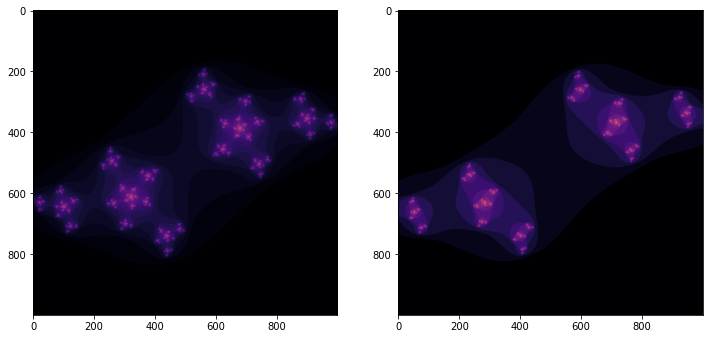

In [181]:
f, axarr = plt.subplots(1,2,figsize=(12, 12))
axarr[0].imshow(julia_set(c=z), cmap='magma')
axarr[1].imshow(julia_set(c=zqc), cmap='magma')
#plt.savefig('plots/2qubit_realhw2_both_bell_state1_U_pi4_-pi3_pi8.png')